<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_dependence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial distribution and spatial dependence of poverty in Bolivia

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

How is multidimensional poverty spread across Bolivia's 343 municipalities and indigenous autonomies, how much does a municipality resemble its neighbours, and did either change between 2012 and 2024? This notebook uses the Multidimensional Poverty Index (MPI; 0–1, higher = poorer) of the *Atlas de los ODS en Bolivia 2026* (SDSN Bolivia), computed from the population censuses of 2012 and 2024, from the `geo4bolivia` package:

1. **Load the data** with `geo4bolivia`
2. **Spatial distribution**: two ways of classifying a map, box-plot breaks and Fisher-Jenks natural breaks, in both periods
3. **Spatial dependence**: spatial weights, the spatial lag, global Moran's I and local clusters and outliers (LISA), in both periods

## 0. Setup

In Google Colab the next cell installs the package and the spatial-analysis libraries (a few seconds). Locally, `uv sync` has installed them already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "libpysal", "esda", "splot"] if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    !pip install -q {pkgs}

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mapclassify as mc

from libpysal import weights
from esda.moran import Moran, Moran_Local
from splot.esda import moran_scatterplot, lisa_cluster
from splot.libpysal import plot_spatial_weights

import geo4bolivia as geo

warnings.filterwarnings("ignore", message="Numba not installed")   # mapclassify works without it
sns.set_theme(style="whitegrid")
SEED = 12345

## 1. Load the data

The MPI with municipal boundaries and names, plus the department of each municipality. The Atlas gives the MPI for two periods, stored as the years 2012 and 2024; `wide=` puts them side by side, one column per year. The map is projected to the observatory's equal-area projection.

In [3]:
YEARS = [2012, 2024]
MPI = {year: f"mpi_{year}" for year in YEARS}      # Multidimensional Poverty Index (0-1, higher = poorer)
LABEL = {year: f"Multidimensional poverty index ({year})" for year in YEARS}

gdf = geo.load("sdg01", variables="sdg1_2_mpi", years=2024, geometry=True)[["geo_id", "name", "geometry"]]
wide = geo.load("sdg01", variables="sdg1_2_mpi", wide="sdg1_2_mpi")
gdf = gdf.merge(wide.rename(columns={f"sdg1_2_mpi{y}": MPI[y] for y in YEARS}), on="geo_id")
units = geo.units("municipality")[["geo_id", "department_id"]]
gdf = gdf.merge(units, on="geo_id")
gdf["department"] = gdf["department_id"].map(geo.units("department").set_index("geo_id")["name"])
gdf = gdf[["geo_id", "name", "department", *MPI.values(), "geometry"]].to_crs(geo.config()["equal_area_crs"])

departments = geo.boundaries("department").to_crs(gdf.crs)
print(len(gdf), "municipalities and indigenous autonomies")
gdf.head()

343 municipalities and indigenous autonomies


,geo_id,name,department,mpi_2012,mpi_2024,geometry
0,BO-01-01-01,Azurduy,Chuquisaca,0.512,0.187,"POLYGON ((21748.153 -439187.901, 21583.382 -43..."
1,BO-01-01-02,Tarvita,Chuquisaca,0.452,0.133,"POLYGON ((-22428.892 -364087.956, -22792.117 -..."
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.267,0.056,"POLYGON ((50112.168 -295041.407, 49559.694 -29..."
3,BO-01-03-01,Huacareta,Chuquisaca,0.346,0.071,"POLYGON ((35331.312 -486863.957, 35115.188 -48..."
4,BO-01-03-02,Monteagudo,Chuquisaca,0.212,0.043,"POLYGON ((70798.318 -431213.236, 70721.787 -43..."


## 2. Spatial distribution

How we cut a continuous variable into classes changes what a map shows. Two classifications from `mapclassify`, each computed separately for each period, so the classes describe where poverty is relatively high or low in that period.

### Box-plot breaks

Box-plot breaks follow the box plot: the classes are the quartiles, and values beyond 1.5 times the interquartile range from the box are flagged as outliers.

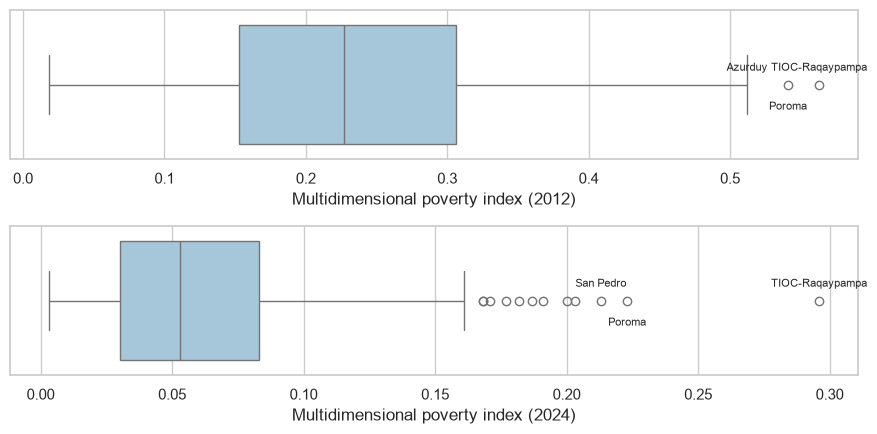

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5))
for ax, year in zip(axes, YEARS):
    sns.boxplot(x=gdf[MPI[year]], color="#9ecae1", ax=ax)
    for i, (_, row) in enumerate(gdf.nlargest(3, MPI[year]).iterrows()):   # label the three poorest
        ax.annotate(row["name"], (row[MPI[year]], 0), xytext=(0, 10 if i % 2 == 0 else -18),
                    textcoords="offset points", ha="center", fontsize=8)
    ax.set(xlabel=LABEL[year])
plt.tight_layout()
plt.show()

In [5]:
for year in YEARS:
    print(year, mc.BoxPlot(gdf[MPI[year]]), "\n")

2012 BoxPlot

   Interval      Count
----------------------
( -inf, -0.08] |     0
(-0.08,  0.15] |    87
( 0.15,  0.23] |    86
( 0.23,  0.31] |    84
( 0.31,  0.54] |    84
( 0.54,  0.56] |     2 

2024 BoxPlot

   Interval      Count
----------------------
( -inf, -0.05] |     0
(-0.05,  0.03] |    88
( 0.03,  0.05] |    84
( 0.05,  0.08] |    87
( 0.08,  0.16] |    72
( 0.16,  0.30] |    12 



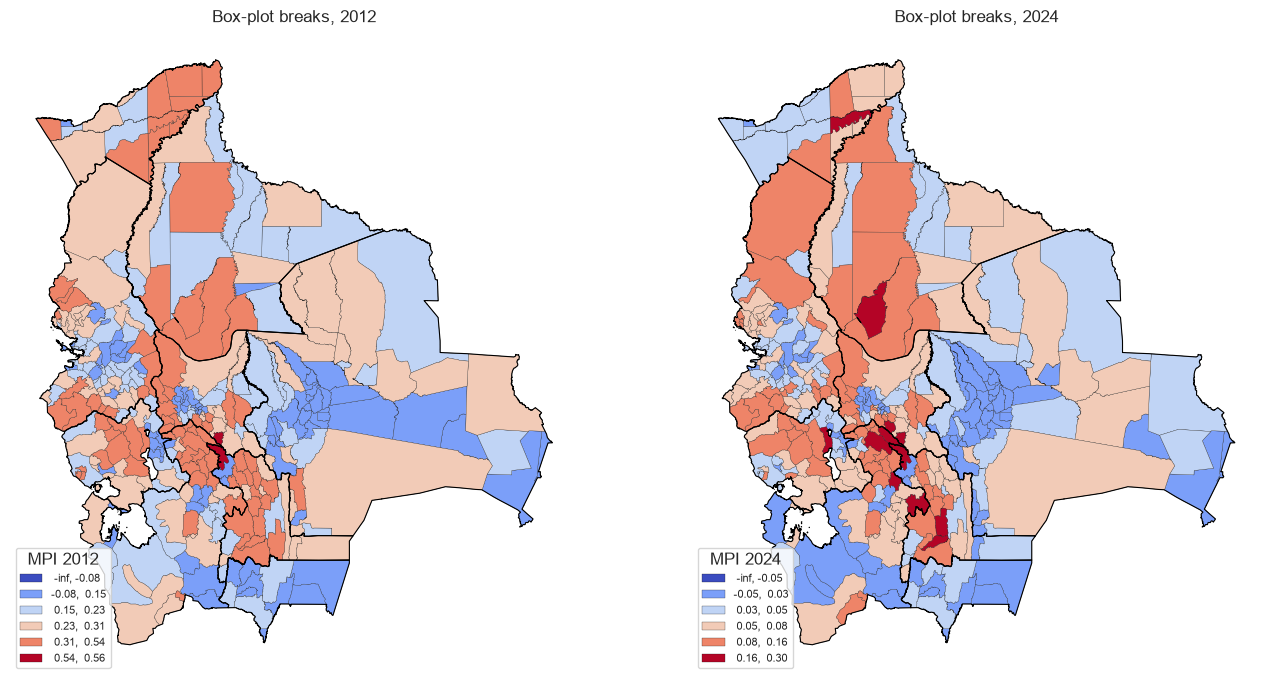

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, year in zip(axes, YEARS):
    gdf.plot(column=MPI[year], scheme="BoxPlot", cmap="coolwarm", edgecolor="k", linewidth=0.2, legend=True,
             legend_kwds={"title": f"MPI {year}", "loc": "lower left", "fontsize": 8}, ax=ax)
    departments.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(f"Box-plot breaks, {year}")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In 2012 the median MPI is 0.227, and the middle half of the municipalities lies between 0.153 and 0.306. The lower whisker would extend below zero, so no municipality is a low outlier (the first class is empty), while two are high outliers above 0.54: TIOC-Raqaypampa (Cochabamba, 0.563) and Poroma (Chuquisaca, 0.541).

By 2024 the whole distribution has shifted down and narrowed: the median is 0.053 and the middle half lies between 0.030 and 0.083. Again there are no low outliers, but now 12 units are high outliers above 0.16, led again by TIOC-Raqaypampa (0.296) and Poroma (0.223), followed by San Pedro (Potosí), El Choro (Oruro) and Vila Vila (Cochabamba). On both maps the upper quartile covers the valleys where Cochabamba, Potosí and Chuquisaca meet and much of the Oruro highlands; in 2012 it also covers 9 of Pando's 15 units, in 2024 only 3. The lower quartile covers the main cities, most of the Santa Cruz lowlands and Tarija.

How much did poverty fall in the poorest units compared with the rest?

In [7]:
fall = 1 - gdf[MPI[2024]] / gdf[MPI[2012]]
high = gdf[MPI[2024]] > mc.BoxPlot(gdf[MPI[2024]]).bins[4]       # above the upper fence
print(f"Relative fall of the MPI, 2012-2024: median {fall.median():.0%}; "
      f"the {high.sum()} high outliers of 2024: {fall[high].min():.0%} to {fall[high].max():.0%}")

Relative fall of the MPI, 2012-2024: median 76%; the 12 high outliers of 2024: 47% to 65%


The typical municipality cut its MPI by 76% between the two periods, while the 12 high outliers of 2024 cut theirs by only 47% to 65%. The poorest units progressed more slowly in relative terms, which is why they stand further from the rest of the distribution in 2024 than in 2012.

### Fisher-Jenks breaks

The Fisher-Jenks algorithm chooses breaks that make classes as homogeneous as possible (it minimises the variance within classes). Here, three classes:

In [8]:
for year in YEARS:
    print(year, mc.FisherJenks(gdf[MPI[year]], k=3), "\n")

2012 FisherJenks

  Interval     Count
--------------------
[0.02, 0.18] |   112
(0.18, 0.31] |   148
(0.31, 0.56] |    83 



2024 FisherJenks

  Interval     Count
--------------------
[0.00, 0.05] |   166
(0.05, 0.11] |   132
(0.11, 0.30] |    45 



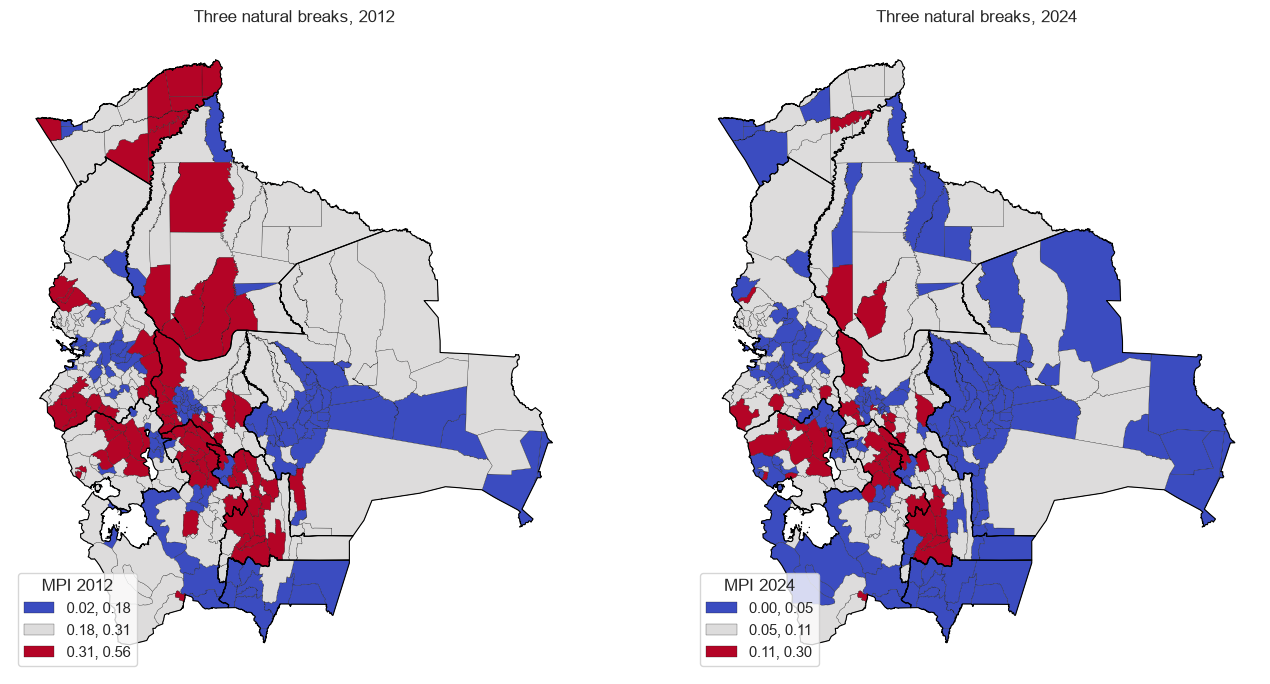

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, year in zip(axes, YEARS):
    gdf.plot(column=MPI[year], scheme="FisherJenks", k=3, cmap="coolwarm", edgecolor="k", linewidth=0.2, legend=True,
             legend_kwds={"title": f"MPI {year}", "loc": "lower left"}, ax=ax)
    departments.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(f"Three natural breaks, {year}")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In 2012 natural breaks put 112 municipalities in the low class (up to 0.18), 148 in the middle class (0.18 to 0.31) and 83 in the high class (above 0.31). In 2024 they put 166 in the low class (up to 0.05), 132 in the middle (0.05 to 0.11) and 45 in the high class (above 0.11). Where box-plot breaks give each quartile about 85 units, natural breaks single out the group of very poor municipalities, and in 2024 that group is smaller and more concentrated: the belt across Chuquisaca, Potosí and Cochabamba and the Oruro highlands, with Pando mostly gone from it.

## 3. Spatial dependence

- To what extent is the poverty of a municipality similar to that of its neighbours?
- To what extent is there an overall pattern of clustering, and did it weaken as poverty fell?
- Where are the statistically significant spatial clusters?
- Where are the statistically significant spatial outliers?

### Spatial connectivity

Each municipality is connected to its 6 nearest neighbours (by the distance between centroids), on all 343 units; the weights are row-standardised, so each neighbour counts 1/6. With k-nearest neighbours no unit is left without neighbours (no islands). The same weights serve both periods.

343 units; islands: 0; connected components: 1


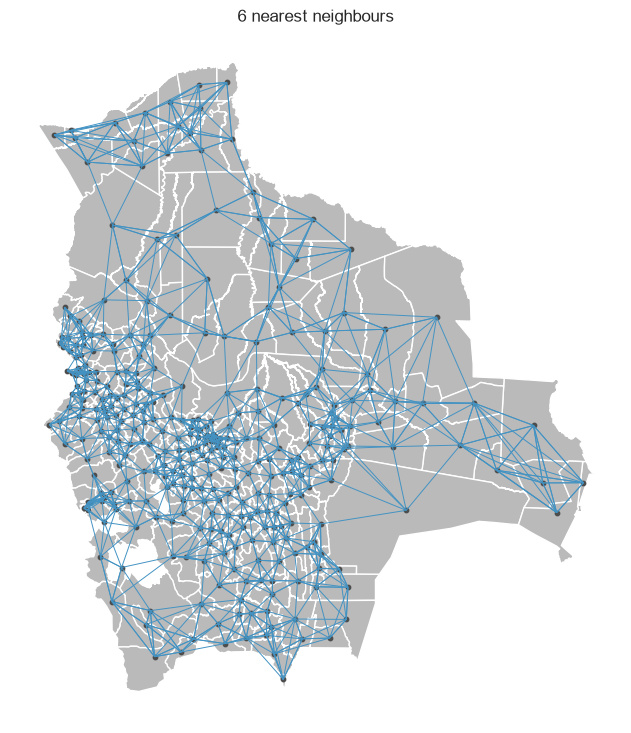

In [10]:
W = weights.KNN.from_dataframe(gdf, k=6)
W.transform = "r"
print(f"{W.n} units; islands: {len(W.islands)}; connected components: {W.n_components}")

fig, ax = plt.subplots(figsize=(9, 9))
plot_spatial_weights(W, gdf, ax=ax)
ax.set_title("6 nearest neighbours")
plt.show()

### Global dependence

The spatial lag is the average poverty of the neighbours. Its relationship with each municipality's own poverty is the Moran scatterplot:

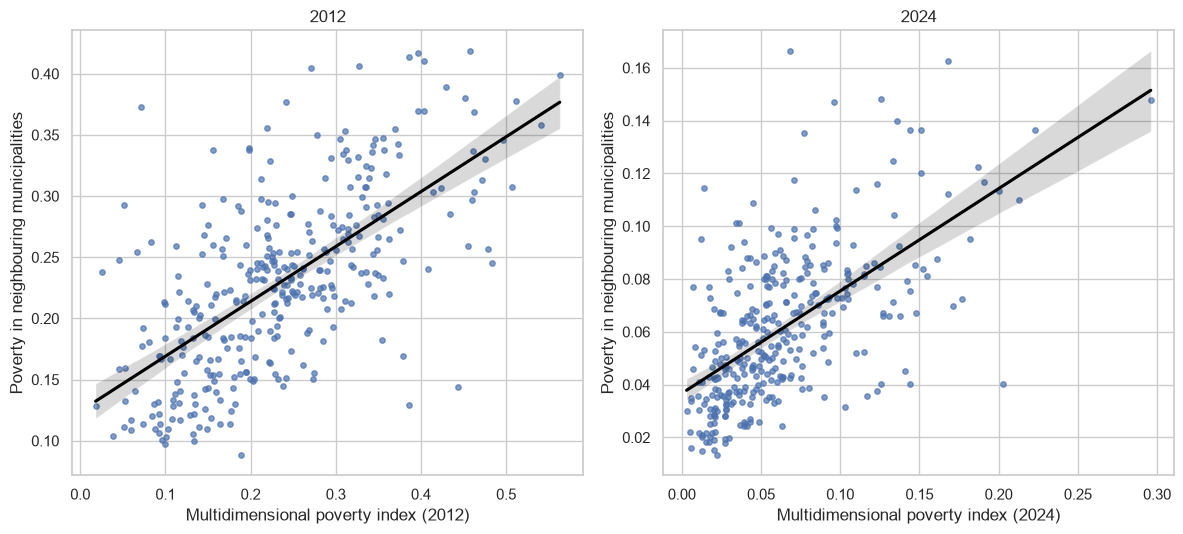

In [11]:
LAG = {year: f"W_mpi_{year}" for year in YEARS}
for year in YEARS:
    gdf[LAG[year]] = weights.lag_spatial(W, gdf[MPI[year]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, year in zip(axes, YEARS):
    sns.regplot(data=gdf, x=MPI[year], y=LAG[year], scatter_kws={"s": 15, "alpha": 0.7},
                line_kws={"color": "black"}, ax=ax)
    ax.set(xlabel=LABEL[year], ylabel="Poverty in neighbouring municipalities", title=str(year))
plt.tight_layout()
plt.show()

In [12]:
np.random.seed(SEED)
globalMoran = {year: Moran(gdf[MPI[year]], W, permutations=999) for year in YEARS}
for year, m in globalMoran.items():
    slope = np.polyfit(gdf[MPI[year]], gdf[LAG[year]], 1)[0]
    print(f"{year}: Moran's I = {m.I:.3f}, pseudo p-value = {m.p_sim:.3f} (999 permutations); "
          f"slope of the scatterplot = {slope:.3f}")

2012: Moran's I = 0.448, pseudo p-value = 0.001 (999 permutations); slope of the scatterplot = 0.448
2024: Moran's I = 0.388, pseudo p-value = 0.001 (999 permutations); slope of the scatterplot = 0.388


Moran's I is 0.45 in 2012 and 0.39 in 2024, both with a pseudo p-value of 0.001, the smallest possible with 999 permutations: no random reshuffle of the values across the map produced as much clustering. With row-standardised weights, Moran's I is exactly the slope of the scatterplot (0.448 and 0.388). In 2012, a municipality whose MPI is 0.1 above the mean has neighbours whose average MPI is, on average, about 0.045 above the mean. Spatial dependence weakened somewhat as poverty fell, but it is still strong in 2024.

### Local dependence

Local Moran's I tests, municipality by municipality, whether its value and its neighbours' are more alike (clusters) or more different (outliers) than a random arrangement would give. Here we use a 10% significance level. "High" and "low" are relative to each period's mean.

In [13]:
localMoran = {year: Moran_Local(gdf[MPI[year]], W, permutations=999, seed=SEED) for year in YEARS}

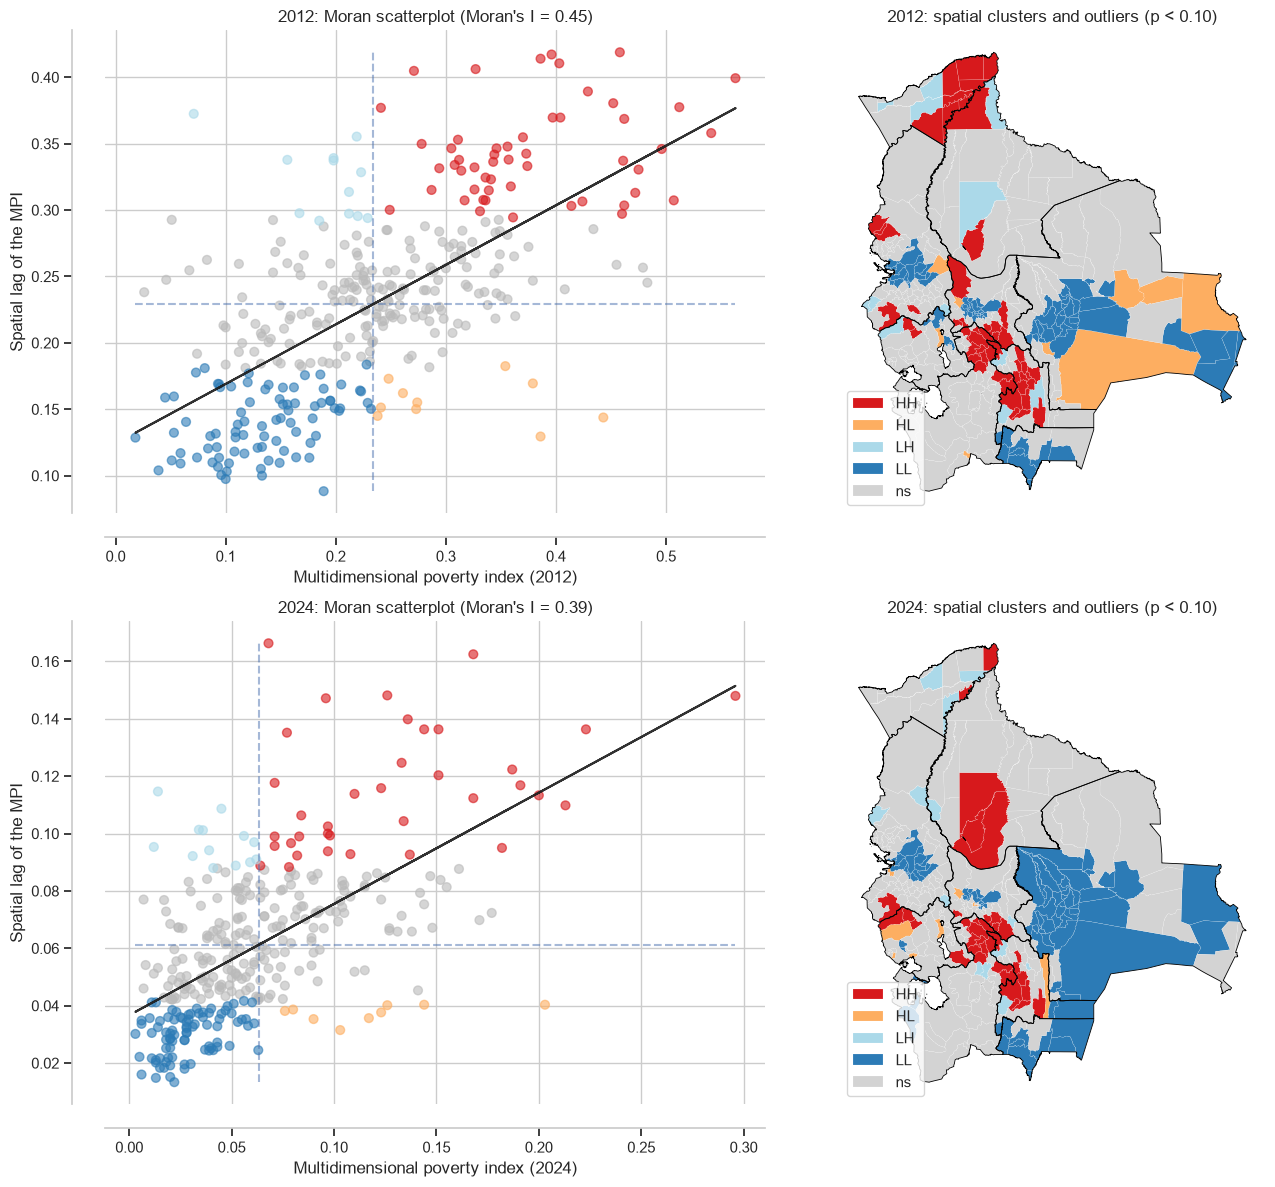

In [14]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

for row, year in zip(axes, YEARS):
    moran_scatterplot(localMoran[year], p=0.10, aspect_equal=False, zstandard=False, ax=row[0])
    lisa_cluster(localMoran[year], gdf, p=0.10, legend_kwds={"loc": "lower left"}, ax=row[1])
    departments.boundary.plot(ax=row[1], color="black", linewidth=0.6)
    row[0].set_xlabel(LABEL[year])
    row[0].set_ylabel("Spatial lag of the MPI")
    row[0].set_title(f"{year}: Moran scatterplot (Moran's I = {globalMoran[year].I:.2f})")
    row[1].set_title(f"{year}: spatial clusters and outliers (p < 0.10)")
plt.tight_layout()
plt.show()

How many municipalities fall in each group, at the 10% and at the stricter 5% level, in each period?

In [15]:
quadrants = {1: "High-high", 2: "Low-high", 3: "Low-low", 4: "High-low"}
order = ["High-high", "Low-low", "High-low", "Low-high", "Not significant"]
groups = {year: pd.Series(localMoran[year].q).map(quadrants) for year in YEARS}
pd.DataFrame({(year, f"p < {p:.2f}"): groups[year].where(localMoran[year].p_sim < p, "Not significant").value_counts()
              for year in YEARS for p in (0.10, 0.05)}).reindex(order)

2012              2024         
                p < 0.10 p < 0.05 p < 0.10 p < 0.05
High-high             52       43       36       27
Low-low               83       70       85       71
High-low              10        7        9        3
Low-high              12        7       13        6
Not significant      186      216      200      236

In [16]:
for year in YEARS:
    gdf[f"cluster_{year}"] = groups[year].where(localMoran[year].p_sim < 0.10, "Not significant").values
pd.concat({year: pd.crosstab(gdf["department"], gdf[f"cluster_{year}"], colnames=["cluster"],
                             margins=True, margins_name="Total")
           for year in YEARS}, axis=1)

2012                                                  \
cluster    High-high High-low Low-high Low-low Not significant Total   
department                                                             
Beni               2        0        2       0              16    20   
Chuquisaca        15        0        3       1              10    29   
Cochabamba         8        1        0      21              18    48   
La Paz             5        2        3      19              58    87   
Oruro              2        1        1       3              28    35   
Pando              8        0        3       0               4    15   
Potosí            12        1        0       0              29    42   
Santa Cruz         0        5        0      31              20    56   
Tarija             0        0        0       8               3    11   
Total             52       10       12      83             186   343   

                2024                                                  
cluster    High-high High-low Low-high Low-low Not significant Total  
department                                                            
Beni               3        0        1       0              16    20  
Chuquisaca         9        1        3       3              13    29  
Cochabamba         5        2        1      12              28    48  
La Paz             1        2        3      16              65    87  
Oruro              4        4        0       2              25    35  
Pando              2        0        3       0              10    15  
Potosí            12        0        2       2              26    42  
Santa Cruz         0        0        0      41              15    56  
Tarija             0        0        0       9               2    11  
Total             36        9       13      85             200   343

At the 10% level, 157 municipalities belong to a significant group in 2012 (30 more than at 5%) and 143 in 2024 (36 more than at 5%):

- **Poverty hotspots (High-high) fell from 52 to 36.** In 2012 they were in Chuquisaca (15), Potosí (12), Pando (8 of its 15 units), Cochabamba (8) and La Paz (5). In 2024 they are in Potosí (12), Chuquisaca (9), Cochabamba (5), Oruro (4) and Beni (3), while Pando keeps 2 and La Paz 1.
- **Clusters of low poverty (Low-low) held steady, 83 and 85**, but shifted east: Santa Cruz went from 31 to 41 and Tarija from 8 to 9 of its 11 municipalities, while Cochabamba fell from 21 to 12 and La Paz from 19 to 16.
- **Outliers: 22 in 2012 and 22 in 2024**: 10, then 9, poorer municipalities with less poor neighbours (High-low), and 12, then 13, less poor municipalities with poorer neighbours (Low-high).

A looser threshold flags more municipalities but also more false positives: with 343 tests at 10%, about 34 would be significant by chance even with no spatial pattern at all. The core clusters are the same at both levels.

## Summary

- The MPI fell sharply between 2012 and 2024 (median 0.227 to 0.053). Box-plot breaks flag 2 high outliers in 2012 and 12 in 2024, led in both by TIOC-Raqaypampa and Poroma; three Fisher-Jenks classes isolate 83 very poor units in 2012 (above 0.31) and 45 in 2024 (above 0.11).
- Poverty is strongly spatially dependent in both periods: Moran's I = 0.45 in 2012 and 0.39 in 2024 (pseudo p-value 0.001) with 6-nearest-neighbour weights on all 343 units.
- At the 10% level, LISA finds 52 poverty hotspots in 2012 and 36 in 2024, now concentrated in Potosí, Chuquisaca and Cochabamba, and 83 and 85 clusters of low poverty, increasingly in Santa Cruz.
- The companion notebook [`esda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb) lists the clusters and outliers at the 5% level and how units moved between groups.